# VisionPort Skilling Sessions 1–5 (CO1)
**Course:** Deep Learning with Accelerated Computing (25CS3112E)

| Session | Topic |
|---|---|
| 1 | Project orientation and deep-learning system lifecycle mapping |
| 2 | End-to-end architecture: FastAPI, Triton, TensorRT, model and GPU |
| 3 | Inference request trace: API input, preprocessing, model execution, response |
| 4 | Repository, Git workflow and PyTorch–CUDA environment setup |
| 5 | COCO dataset exploration: categories and bounding-box annotations |

**Before running:** Runtime → Change runtime type → **T4 GPU**, then Run all.
Fill in your name and roll number in the next cell.

In [1]:
STUDENT_NAME = "V SRI RITWIK"
ROLL_NO = "2520080051"
print(STUDENT_NAME, ROLL_NO)

V SRI RITWIK 2520080051


---
# Session 1: Project orientation and lifecycle mapping
**Goal:** one-page lifecycle map (data, training artefacts, inference artefacts, deployment components) and the dependency between training, optimisation and serving.

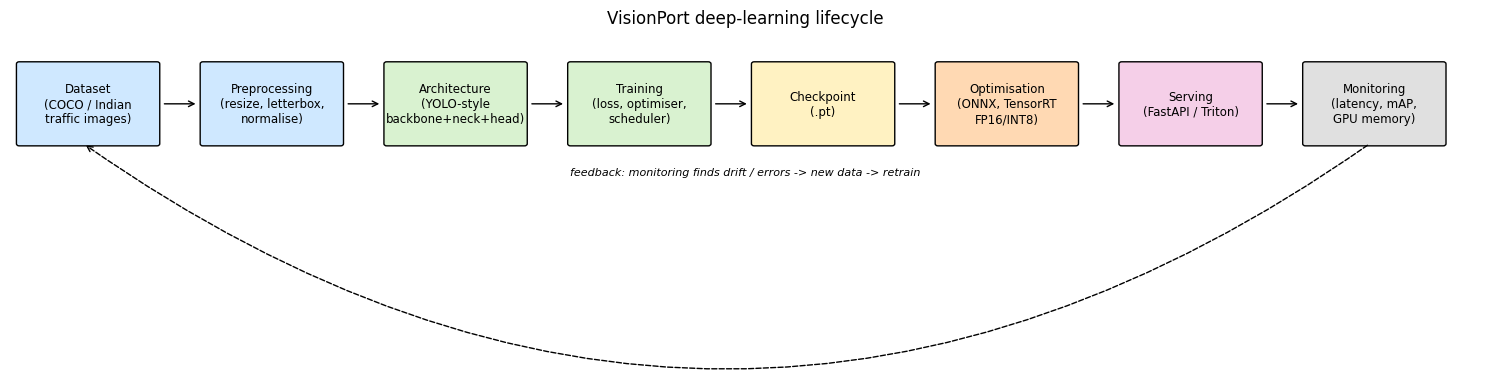

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

stages = [
    ("Dataset\n(COCO / Indian\ntraffic images)", "#cfe8ff"),
    ("Preprocessing\n(resize, letterbox,\nnormalise)", "#cfe8ff"),
    ("Architecture\n(YOLO-style\nbackbone+neck+head)", "#d9f2d0"),
    ("Training\n(loss, optimiser,\nscheduler)", "#d9f2d0"),
    ("Checkpoint\n(.pt)", "#fff2c2"),
    ("Optimisation\n(ONNX, TensorRT\nFP16/INT8)", "#ffd9b3"),
    ("Serving\n(FastAPI / Triton)", "#f5cfe8"),
    ("Monitoring\n(latency, mAP,\nGPU memory)", "#e0e0e0"),
]
fig, ax = plt.subplots(figsize=(15, 3.2))
ax.set_xlim(0, len(stages) * 2); ax.set_ylim(0, 2); ax.axis("off")
for i, (label, col) in enumerate(stages):
    x = i * 2 + 0.1
    ax.add_patch(FancyBboxPatch((x, 0.45), 1.5, 1.1, boxstyle="round,pad=0.03", fc=col, ec="black"))
    ax.text(x + 0.75, 1.0, label, ha="center", va="center", fontsize=8.5)
    if i < len(stages) - 1:
        ax.annotate("", xy=(x + 1.95, 1.0), xytext=(x + 1.55, 1.0), arrowprops=dict(arrowstyle="->"))
ax.annotate("", xy=(0.8, 0.45), xytext=(len(stages)*2 - 1.2, 0.45),
            arrowprops=dict(arrowstyle="->", linestyle="dashed", connectionstyle="arc3,rad=-0.35"))
ax.text(len(stages), 0.02, "feedback: monitoring finds drift / errors -> new data -> retrain", ha="center", fontsize=8, style="italic")
ax.set_title("VisionPort deep-learning lifecycle", fontsize=12)
plt.tight_layout(); plt.savefig("lifecycle_map.png", dpi=150); plt.show()

In [3]:
import pandas as pd
artefacts = pd.DataFrame([
    ["Dataset + annotations", "COCO JSON, images",              "Training, evaluation",      "Training"],
    ["Model architecture",    "Python/YAML definition",         "Training, export",          "Training"],
    ["Trained checkpoint",    ".pt (weights, optimiser state)", "Resume training, export",   "Training"],
    ["ONNX graph",            ".onnx",                          "ONNX Runtime, TensorRT",    "Optimisation"],
    ["TensorRT engine",       ".engine / .plan (GPU-specific)", "Triton / runtime serving",  "Optimisation"],
    ["Triton model repo",     "config.pbtxt + engine",          "Triton Inference Server",   "Serving"],
    ["API service",           "FastAPI app (visionport.py)",    "Client requests",           "Serving"],
], columns=["Artefact", "Format", "Used by", "Phase"])
artefacts

,Artefact,Format,Used by,Phase
0,Dataset + annotations,"COCO JSON, images","Training, evaluation",Training
1,Model architecture,Python/YAML definition,"Training, export",Training
2,Trained checkpoint,".pt (weights, optimiser state)","Resume training, export",Training
3,ONNX graph,.onnx,"ONNX Runtime, TensorRT",Optimisation
4,TensorRT engine,.engine / .plan (GPU-specific),Triton / runtime serving,Optimisation
5,Triton model repo,config.pbtxt + engine,Triton Inference Server,Serving
6,API service,FastAPI app (visionport.py),Client requests,Serving


### Dependency: training → optimisation → serving
- **Training** decides accuracy and produces the checkpoint. Everything downstream inherits its quality.
- **Optimisation** (ONNX export, FP16/INT8, TensorRT) trades a little accuracy for lower latency and memory. It needs the checkpoint, the exact input/output contract and calibration data that look like real traffic.
- **Serving** exposes the optimised engine behind an API. Its latency and throughput depend on the engine, batching and preprocessing.
- A change upstream (new classes, new input size) forces re-export and re-build downstream. A TensorRT engine is tied to GPU, TensorRT version and precision, so it is not interchangeable with a checkpoint or an ONNX file.

---
# Session 2: End-to-end VisionPort architecture
Runs the provided `visionport.py` (FastAPI + YOLOv8n) in Colab and calls it over HTTP.
Triton and TensorRT are covered conceptually here and built in later sessions (8–16).

In [4]:
!pip -q install ultralytics fastapi uvicorn python-multipart requests

In [5]:
%%writefile visionport.py
import io
import cv2
import numpy as np
from fastapi import FastAPI, File, UploadFile
from fastapi.responses import StreamingResponse
from ultralytics import YOLO

# Initialize FastAPI and load the object detection model
app = FastAPI(title="Indian Traffic Detection API")
model = YOLO("yolov8n.pt")  # Swap with custom-trained weights (e.g., 'best.pt') for specific Indian vehicles


@app.post("/detect/")
async def detect_objects(file: UploadFile = File(...)):
    # 1. Read the uploaded image bytes
    contents = await file.read()
    nparr = np.frombuffer(contents, np.uint8)
    img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

    # 2. Run Object Detection inference
    results = model(img)

    # 3. Annotate the image with bounding boxes and labels
    annotated_img = results[0].plot()

    # 4. Stream the processed image back in real time
    _, encoded_img = cv2.imencode(".jpg", annotated_img)
    return StreamingResponse(io.BytesIO(encoded_img.tobytes()), media_type="image/jpeg")


if __name__ == "__main__":
    import uvicorn

    uvicorn.run(app, host="0.0.0.0", port=8000)

Writing visionport.py


In [6]:
import subprocess, time, requests, sys

server = subprocess.Popen([sys.executable, "-m", "uvicorn", "visionport:app", "--port", "8000"],
                          stdout=open("server.log", "w"), stderr=subprocess.STDOUT)
for _ in range(60):
    try:
        if requests.get("http://127.0.0.1:8000/docs", timeout=1).status_code == 200:
            print("VisionPort API is up"); break
    except Exception:
        time.sleep(1)
else:
    print(open("server.log").read())

VisionPort API is up


HTTP 200 | round trip 16077 ms | 357 KB returned


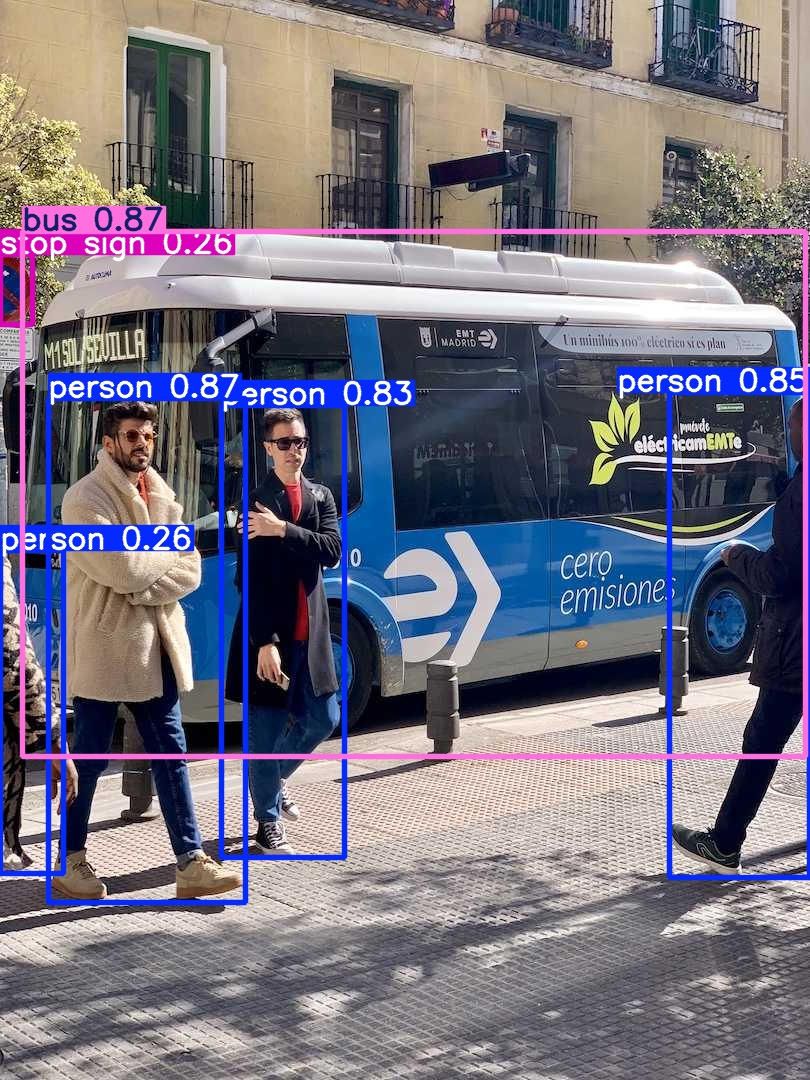

In [7]:
import os
if not os.path.exists("sample.jpg"):
    !wget -q https://ultralytics.com/images/bus.jpg -O sample.jpg   # replace with your own traffic image via the Colab file panel

import cv2, numpy as np
from IPython.display import Image, display

t0 = time.perf_counter()
with open("sample.jpg", "rb") as f:
    r = requests.post("http://127.0.0.1:8000/detect/", files={"file": ("sample.jpg", f, "image/jpeg")})
print("HTTP", r.status_code, f"| round trip {(time.perf_counter()-t0)*1000:.0f} ms | {len(r.content)/1024:.0f} KB returned")
open("annotated.jpg", "wb").write(r.content)
display(Image("annotated.jpg"))

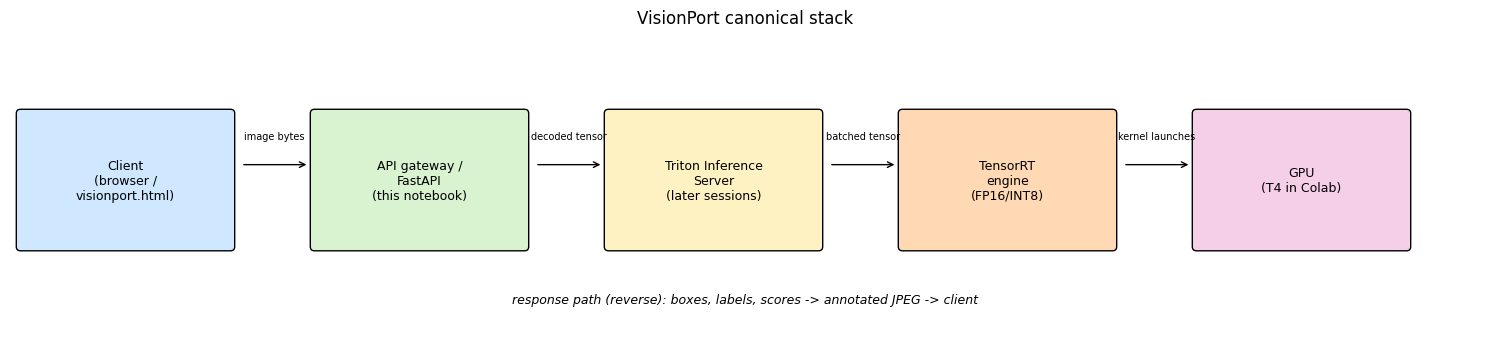

In [8]:
fig, ax = plt.subplots(figsize=(15, 3.6)); ax.axis("off"); ax.set_xlim(0, 14); ax.set_ylim(0, 3)
layers = [("Client\n(browser /\nvisionport.html)", "#cfe8ff", "image bytes"),
          ("API gateway /\nFastAPI\n(this notebook)", "#d9f2d0", "decoded tensor"),
          ("Triton Inference\nServer\n(later sessions)", "#fff2c2", "batched tensor"),
          ("TensorRT\nengine\n(FP16/INT8)", "#ffd9b3", "kernel launches"),
          ("GPU\n(T4 in Colab)", "#f5cfe8", "raw predictions")]
for i, (t, c, lab) in enumerate(layers):
    x = i * 2.8 + 0.1
    ax.add_patch(FancyBboxPatch((x, 0.9), 2.0, 1.3, boxstyle="round,pad=0.04", fc=c, ec="black"))
    ax.text(x + 1.0, 1.55, t, ha="center", va="center", fontsize=9)
    if i < 4:
        ax.annotate("", xy=(x + 2.75, 1.7), xytext=(x + 2.1, 1.7), arrowprops=dict(arrowstyle="->"))
        ax.text(x + 2.42, 1.95, lab, ha="center", fontsize=7)
ax.text(7, 0.35, "response path (reverse): boxes, labels, scores -> annotated JPEG -> client", ha="center", fontsize=9, style="italic")
ax.set_title("VisionPort canonical stack", fontsize=12)
plt.tight_layout(); plt.savefig("architecture.png", dpi=150); plt.show()

### Responsibility of each layer
| Layer | Responsibility | Artefact exchanged |
|---|---|---|
| Client | Upload image, show result | JPEG bytes (multipart) |
| FastAPI | Validation, decode, call model, encode response | NumPy BGR array, JPEG |
| Triton | Dynamic batching, scheduling, multi-model serving | Tensors + `config.pbtxt` |
| TensorRT engine | Fused, reduced-precision kernels | `.engine` file |
| GPU | Executes CUDA kernels | Device memory tensors |

In this notebook FastAPI calls Ultralytics PyTorch directly. In the full VisionPort, FastAPI would forward tensors to Triton, which runs the TensorRT engine.

---
# Session 3: Inference request trace
Trace one request through validation, decode, letterbox, tensor preparation, model call, postprocessing and serialisation. We record data format, tensor shape and time at each stage.

In [9]:
import json, io
import torch
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

def letterbox(img, new=640, color=114):
    h, w = img.shape[:2]
    r = min(new / h, new / w)
    nh, nw = int(round(h * r)), int(round(w * r))
    resized = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR)
    canvas = np.full((new, new, 3), color, dtype=np.uint8)
    top, left = (new - nh) // 2, (new - nw) // 2
    canvas[top:top+nh, left:left+nw] = resized
    return canvas

def traced_request(path, model, device="cuda" if torch.cuda.is_available() else "cpu"):
    trace = []
    def rec(stage, t0, fmt, shape):
        trace.append(dict(stage=stage, ms=(time.perf_counter()-t0)*1000, data_format=fmt, shape=str(shape)))

    t = time.perf_counter(); raw = open(path, "rb").read()
    assert len(raw) > 0 and raw[:2] == b"\xff\xd8", "not a JPEG"
    rec("1 request validation", t, "bytes (JPEG)", (len(raw),))

    t = time.perf_counter(); img = cv2.imdecode(np.frombuffer(raw, np.uint8), cv2.IMREAD_COLOR)
    rec("2 image decode", t, "uint8 BGR HWC", img.shape)

    t = time.perf_counter(); lb = letterbox(img)
    rec("3 letterbox resize", t, "uint8 BGR HWC", lb.shape)

    t = time.perf_counter()
    x = torch.from_numpy(lb[:, :, ::-1].copy()).permute(2, 0, 1).float().div(255).unsqueeze(0)
    rec("4 tensor prep (CPU)", t, "float32 NCHW [0,1]", tuple(x.shape))

    t = time.perf_counter(); x = x.to(device)
    if device == "cuda": torch.cuda.synchronize()
    rec("5 host->device copy", t, f"float32 NCHW on {device}", tuple(x.shape))

    t = time.perf_counter(); res = model(img, verbose=False)
    if device == "cuda": torch.cuda.synchronize()
    rec("6 model call (pre+infer+NMS)", t, "Results object", "-")
    sp = res[0].speed

    t = time.perf_counter(); b = res[0].boxes
    dets = [dict(cls=model.names[int(c)], conf=round(float(s), 3), xyxy=[round(v, 1) for v in xy.tolist()])
            for c, s, xy in zip(b.cls, b.conf, b.xyxy)]
    rec("7 postprocess to dicts", t, "list[dict]", (len(dets), 6))

    t = time.perf_counter(); body = json.dumps(dets)
    rec("8 response serialisation", t, "JSON str", (len(body),))
    return trace, sp, dets

traced_request("sample.jpg", model)   # warm-up (CUDA init, cuDNN autotune)
trace, speed, dets = traced_request("sample.jpg", model)
df = pd.DataFrame(trace)
display(df.round(2))
print("Ultralytics internal split (ms):", {k: round(v, 2) for k, v in speed.items()})
print(f"{len(dets)} detections:", sorted({d['cls'] for d in dets}))

,stage,ms,data_format,shape
0,1 request validation,0.16,bytes (JPEG),"(137419,)"
1,2 image decode,9.48,uint8 BGR HWC,"(1080, 810, 3)"
2,3 letterbox resize,1.81,uint8 BGR HWC,"(640, 640, 3)"
3,4 tensor prep (CPU),13.07,"float32 NCHW [0,1]","(1, 3, 640, 640)"
4,5 host->device copy,1.99,float32 NCHW on cuda,"(1, 3, 640, 640)"
5,6 model call (pre+infer+NMS),16.51,Results object,-
6,7 postprocess to dicts,0.88,list[dict],"(6, 6)"
7,8 response serialisation,0.06,JSON str,"(424,)"


Ultralytics internal split (ms): {'preprocess': 2.75, 'inference': 10.76, 'postprocess': 2.04}
6 detections: ['bus', 'person', 'stop sign']


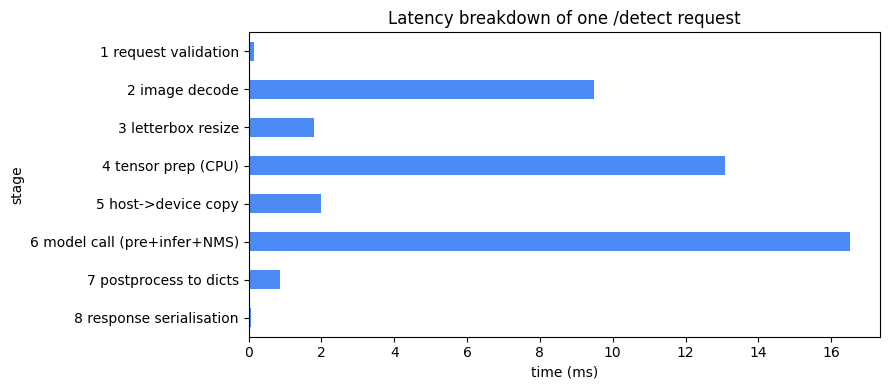

Slowest stage: 6 model call (pre+infer+NMS)


In [10]:
ax = df.set_index("stage")["ms"].plot.barh(figsize=(9, 4), color="#4c8bf5")
ax.invert_yaxis(); ax.set_xlabel("time (ms)"); ax.set_title("Latency breakdown of one /detect request")
plt.tight_layout(); plt.savefig("latency_breakdown.png", dpi=150); plt.show()
slowest = df.loc[df.ms.idxmax(), "stage"]
print("Slowest stage:", slowest)

### Likely latency points
- **Preprocessing (decode, letterbox, tensor prep):** CPU-bound. Grows with image resolution, and a Python loop here hurts throughput.
- **Host→device transfer:** PCIe copy. Reduced by batching and pinned memory.
- **Inference:** GPU compute; optimised later with FP16/INT8 and TensorRT.
- **Postprocess/NMS and serialisation:** CPU work, small but visible once inference is fast.
- **Queue time in the server** is not shown here; it appears under load and is addressed by dynamic batching in Triton.

(After you run the cell above, replace this with a sentence about which stage was slowest in *your* run.)

---
# Session 4: Repository, Git workflow and PyTorch–CUDA environment

In [11]:
!nvidia-smi
!nvcc --version | tail -n 2

Mon Nov 23 09:16:58 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P0             27W /   70W |     347MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [12]:
import torch, platform, sys
print("Python      :", sys.version.split()[0], "|", platform.platform())
print("PyTorch     :", torch.__version__)
print("CUDA avail. :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("CUDA (torch):", torch.version.cuda)
    print("cuDNN       :", torch.backends.cudnn.version())
    print("GPU         :", torch.cuda.get_device_name(0))
    p = torch.cuda.get_device_properties(0)
    print(f"GPU memory  : {p.total_memory/1e9:.1f} GB | SMs: {p.multi_processor_count} | capability {p.major}.{p.minor}")
    a = torch.randn(2048, 2048, device="cuda"); b = a @ a; torch.cuda.synchronize()
    print("GPU matmul smoke test OK:", tuple(b.shape))

Python      : 3.13.16 | Linux-6.6.159+-x86_64-with-glibc2.39
PyTorch     : 2.14.1+cu130
CUDA avail. : True
CUDA (torch): 13.0
cuDNN       : 92800
GPU         : Tesla T4
GPU memory  : 15.6 GB | SMs: 40 | capability 7.5
GPU matmul smoke test OK: (2048, 2048)


In [13]:
import os
PROJECT = "/content/visionport-project"
for d in ["data/raw", "data/processed", "src/data", "src/models", "src/training", "src/serving",
          "configs", "checkpoints", "exports/onnx", "exports/tensorrt", "triton/model_repository",
          "notebooks", "reports", "tests"]:
    os.makedirs(f"{PROJECT}/{d}", exist_ok=True)
open(f"{PROJECT}/README.md", "w").write("# VisionPort\nIndian traffic detection: training, optimisation and serving.\n")
open(f"{PROJECT}/.gitignore", "w").write("data/raw/\ncheckpoints/*.pt\nexports/\n__pycache__/\n*.engine\n")
!cp visionport.py {PROJECT}/src/serving/
!cd {PROJECT} && find . -not -path "./.git*" | sort

.
./checkpoints
./configs
./data
./data/processed
./data/raw
./exports
./exports/onnx
./exports/tensorrt
./notebooks
./README.md
./reports
./src
./src/data
./src/models
./src/serving
./src/serving/visionport.py
./src/training
./tests
./triton
./triton/model_repository


In [14]:
!pip freeze | grep -iE "^(torch|torchvision|ultralytics|fastapi|uvicorn|numpy|opencv|onnx|pandas|matplotlib)" > {PROJECT}/requirements.txt
!cat {PROJECT}/requirements.txt

fastapi==0.141.1
matplotlib==3.10.0
matplotlib-inline==0.2.2
matplotlib-venn==1.1.2
numpy==2.4.6
opencv-contrib-python==4.14.0.94
opencv-python==5.0.0.93
opencv-python-headless==5.0.0.93
pandas==2.2.3
pandas-datareader==0.11.1
pandas-gbq==0.30.0
pandas-stubs==2.2.3.250527
torch==2.14.1+cu130
torchao==0.10.0
torchaudio==2.11.0+cu130
torchcodec==0.17.0+cu130
torchdata==0.11.0
torchsummary==1.5.1
torchtune==0.6.1
torchvision==0.29.1+cu130
ultralytics==8.4.216
ultralytics-platform==0.1.121
ultralytics-thop==2.2.5
uvicorn==0.54.0


In [15]:
%%bash
cd /content/visionport-project
git init -q -b main 2>/dev/null || git init -q
git config user.name "VisionPort Student"
git config user.email "student@example.com"
git add .
git commit -q -m "Session 4: project skeleton, requirements, serving stub"
git checkout -q -b feature/dataset-audit
echo "# dataset audit notes" > reports/dataset_audit.md
git add reports/dataset_audit.md
git commit -q -m "Add dataset audit notes (branch demo)"
git checkout -q main
git merge -q --no-ff feature/dataset-audit -m "Merge dataset audit branch"
git log --oneline --graph --all

*   aeead06 Merge dataset audit branch
|\  
| * c52f42b Add dataset audit notes (branch demo)
|/  
* 229ec12 Session 4: project skeleton, requirements, serving stub


In [16]:
env_report = {
    "student": STUDENT_NAME, "roll_no": ROLL_NO,
    "python": sys.version.split()[0], "torch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_runtime": torch.version.cuda,
    "cudnn": torch.backends.cudnn.version(),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
}
json.dump(env_report, open(f"{PROJECT}/reports/environment_report.json", "w"), indent=2)
print(json.dumps(env_report, indent=2))

{
  "student": "V SRI RITWIK",
  "roll_no": "2520080051",
  "python": "3.13.16",
  "torch": "2.14.1+cu130",
  "cuda_available": true,
  "cuda_runtime": "13.0",
  "cudnn": 92800,
  "gpu": "Tesla T4"
}


---
# Session 5: COCO dataset exploration
Loads the COCO annotation JSON, lists categories, inspects image records and draws bounding boxes for traffic classes.

> COCO is used here as the stand-in dataset. If your lab provides an Indian-traffic COCO-format JSON, set `ANN_PATH` and `IMG_DIR` below and the rest works unchanged.

In [17]:
%%bash
cd /content
if [ ! -f instances_val2017.json ]; then
  wget -q http://images.cocodataset.org/annotations/annotations_trainval2017.zip
  unzip -o -j -q annotations_trainval2017.zip annotations/instances_val2017.json
  rm annotations_trainval2017.zip
fi
ls -lh instances_val2017.json

-rw-rw-r-- 1 root root 20M Sep  1  2017 instances_val2017.json


In [18]:
ANN_PATH = "/content/instances_val2017.json"
coco = json.load(open(ANN_PATH))
print("Top-level keys:", list(coco.keys()))
print(f"images={len(coco['images'])}  annotations={len(coco['annotations'])}  categories={len(coco['categories'])}")
print("\nImage record     :", coco["images"][0])
print("Annotation record:", {k: v for k, v in coco["annotations"][0].items() if k != "segmentation"})
print("Category record  :", coco["categories"][0])

Top-level keys: ['info', 'licenses', 'images', 'annotations', 'categories']
images=5000  annotations=36781  categories=80

Image record     : {'license': 4, 'file_name': '000000397133.jpg', 'coco_url': 'http://images.cocodataset.org/val2017/000000397133.jpg', 'height': 427, 'width': 640, 'date_captured': '2013-11-14 17:02:52', 'flickr_url': 'http://farm7.staticflickr.com/6116/6255196340_da26cf2c9e_z.jpg', 'id': 397133}
Annotation record: {'area': 702.1057499999998, 'iscrowd': 0, 'image_id': 289343, 'bbox': [473.07, 395.93, 38.65, 28.67], 'category_id': 18, 'id': 1768}
Category record  : {'supercategory': 'person', 'id': 1, 'name': 'person'}


**COCO JSON structure**
- `images`: `id`, `file_name`, `width`, `height`, `coco_url`
- `annotations`: `id` (annotation ID), `image_id`, `category_id`, `bbox = [x, y, width, height]` (top-left origin, pixels), `area`, `iscrowd`
- `categories`: `id`, `name`, `supercategory`. Category IDs are **not** contiguous 0..79; models usually need a remap.

In [19]:
cats = {c["id"]: c["name"] for c in coco["categories"]}
print(len(cats), "categories")
print(pd.DataFrame(coco["categories"]).groupby("supercategory")["name"].apply(list).to_string())

TRAFFIC = ["person", "bicycle", "car", "motorcycle", "bus", "truck", "traffic light", "stop sign"]
traffic_ids = {i for i, n in cats.items() if n in TRAFFIC}
print("\nTraffic category IDs:", {cats[i]: i for i in sorted(traffic_ids)})

80 categories
supercategory
accessory          [backpack, umbrella, handbag, tie, suitcase]
animal        [bird, cat, dog, horse, sheep, cow, elephant, ...
appliance        [microwave, oven, toaster, sink, refrigerator]
electronic    [tv, laptop, mouse, remote, keyboard, cell phone]
food          [banana, apple, sandwich, orange, broccoli, ca...
furniture     [chair, couch, potted plant, bed, dining table...
indoor        [book, clock, vase, scissors, teddy bear, hair...
kitchen       [bottle, wine glass, cup, fork, knife, spoon, ...
outdoor       [traffic light, fire hydrant, stop sign, parki...
person                                                 [person]
sports        [frisbee, skis, snowboard, sports ball, kite, ...
vehicle       [bicycle, car, motorcycle, airplane, bus, trai...

Traffic category IDs: {'person': 1, 'bicycle': 2, 'car': 3, 'motorcycle': 4, 'bus': 6, 'truck': 8, 'traffic light': 10, 'stop sign': 13}


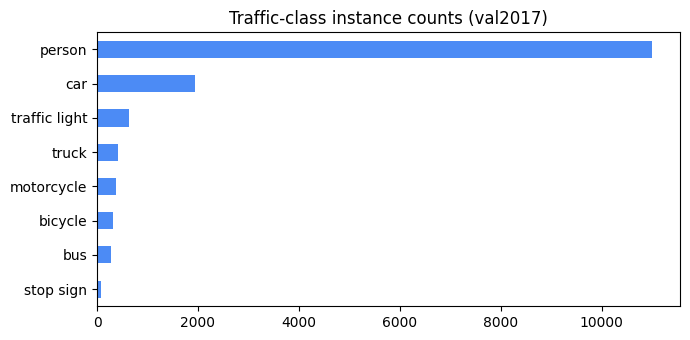

Selected image IDs: [254814, 490936, 122166, 460147]
254814 000000254814.jpg 640 x 480 -> 43 traffic objects
490936 000000490936.jpg 480 x 640 -> 35 traffic objects
122166 000000122166.jpg 640 x 480 -> 28 traffic objects
460147 000000460147.jpg 640 x 424 -> 27 traffic objects


In [20]:
from collections import Counter, defaultdict
imgs = {im["id"]: im for im in coco["images"]}
per_img = defaultdict(list)
for a in coco["annotations"]:
    per_img[a["image_id"]].append(a)

cnt = Counter(cats[a["category_id"]] for a in coco["annotations"] if a["category_id"] in traffic_ids)
pd.Series(cnt).sort_values().plot.barh(figsize=(7, 3.5), color="#4c8bf5", title="Traffic-class instance counts (val2017)")
plt.tight_layout(); plt.show()

def traffic_score(iid):
    anns = per_img[iid]
    kinds = {a["category_id"] for a in anns if a["category_id"] in traffic_ids}
    return len(kinds), sum(a["category_id"] in traffic_ids for a in anns)
top = sorted(per_img, key=traffic_score, reverse=True)[:4]
print("Selected image IDs:", top)
for i in top: print(i, imgs[i]["file_name"], imgs[i]["width"], "x", imgs[i]["height"], "->", traffic_score(i)[1], "traffic objects")

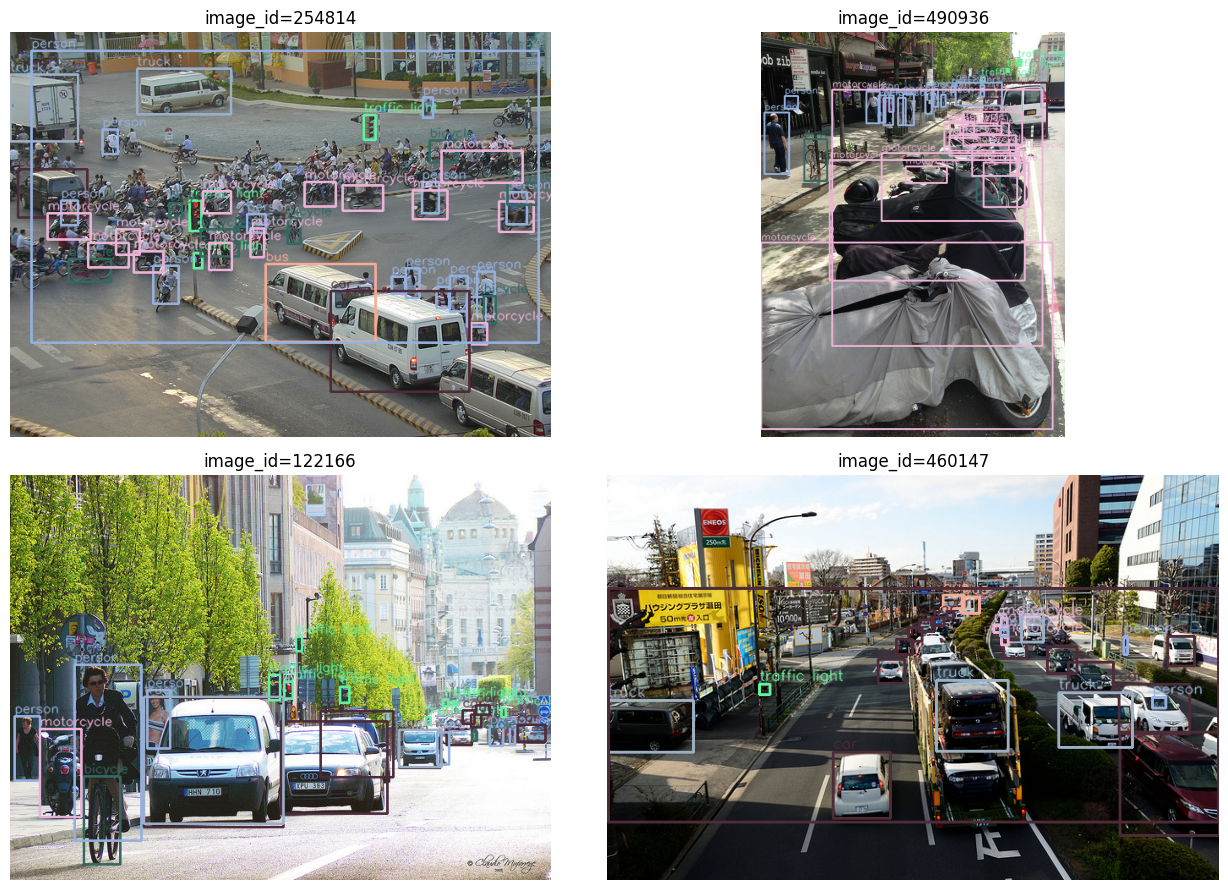

In [21]:
IMG_DIR = "/content/coco_samples"; os.makedirs(IMG_DIR, exist_ok=True)

def fetch(iid):
    im = imgs[iid]; p = f"{IMG_DIR}/{im['file_name']}"
    if not os.path.exists(p):
        open(p, "wb").write(requests.get(im["coco_url"], timeout=30).content)
    return p

rng = np.random.default_rng(0)
colors = {n: tuple(int(v) for v in rng.integers(40, 255, 3)) for n in TRAFFIC}

def draw(iid):
    img = cv2.imread(fetch(iid))
    for a in per_img[iid]:
        if a["category_id"] not in traffic_ids: continue
        x, y, w, h = a["bbox"]                       # COCO: xywh
        x1, y1, x2, y2 = int(x), int(y), int(x + w), int(y + h)
        n = cats[a["category_id"]]
        cv2.rectangle(img, (x1, y1), (x2, y2), colors[n], 2)
        cv2.putText(img, n, (x1, max(12, y1 - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, colors[n], 1, cv2.LINE_AA)
    return img[:, :, ::-1]

fig, axs = plt.subplots(2, 2, figsize=(13, 9))
for ax, iid in zip(axs.ravel(), top):
    ax.imshow(draw(iid)); ax.set_title(f"image_id={iid}"); ax.axis("off")
plt.tight_layout(); plt.savefig("coco_boxes.png", dpi=130); plt.show()

In [22]:
# Verification: image IDs, category IDs, bounding boxes interpreted correctly
errors = []
ann_ids = [a["id"] for a in coco["annotations"]]
assert len(ann_ids) == len(set(ann_ids)), "duplicate annotation IDs"
for a in coco["annotations"]:
    im = imgs.get(a["image_id"])
    if im is None: errors.append(("orphan image_id", a["id"])); continue
    if a["category_id"] not in cats: errors.append(("unknown category", a["id"])); continue
    x, y, w, h = a["bbox"]
    if w <= 0 or h <= 0: errors.append(("non-positive box", a["id"]))
    elif x < 0 or y < 0 or x + w > im["width"] + 1 or y + h > im["height"] + 1: errors.append(("box outside image", a["id"]))
print("Annotations checked:", len(ann_ids), "| issues:", len(errors))
print(Counter(e[0] for e in errors))

# one explicit worked example
a = next(a for a in per_img[top[0]] if a["category_id"] in traffic_ids)
x, y, w, h = a["bbox"]
print(f"\nExample: {cats[a['category_id']]} (cat_id {a['category_id']}) on image {a['image_id']}")
print(f"  COCO xywh = {[round(v,1) for v in a['bbox']]}  ->  xyxy = {[round(v,1) for v in (x, y, x+w, y+h)]}")
print(f"  YOLO normalised cx,cy,w,h = {[round(v,4) for v in ((x+w/2)/imgs[a['image_id']]['width'], (y+h/2)/imgs[a['image_id']]['height'], w/imgs[a['image_id']]['width'], h/imgs[a['image_id']]['height'])]}")

Annotations checked: 36781 | issues: 0
Counter()

Example: bicycle (cat_id 2) on image 254814
  COCO xywh = [69.9, 269.2, 49.4, 27.1]  ->  xyxy = [69.9, 269.2, 119.4, 296.2]
  YOLO normalised cx,cy,w,h = [0.1479, 0.589, 0.0772, 0.0564]


### Viva notes
- COCO boxes are `[x, y, w, h]` from the top-left; YOLO labels are normalised `[cx, cy, w, h]` and use contiguous class indices.
- Category IDs in COCO skip numbers (80 classes, IDs up to 90). Always map through the `categories` list.
- Annotations with `iscrowd=1` describe groups and need separate handling in training and evaluation.
- Indian traffic differs from COCO (auto-rickshaws, dense two-wheelers, mixed lanes); a custom dataset or fine-tuning is needed for those classes.

In [23]:
server.terminate()
print("Server stopped. Files to submit: lifecycle_map.png, architecture.png, latency_breakdown.png, coco_boxes.png,")
print("visionport-project/ (repo + requirements.txt + reports/environment_report.json)")

Server stopped. Files to submit: lifecycle_map.png, architecture.png, latency_breakdown.png, coco_boxes.png,
visionport-project/ (repo + requirements.txt + reports/environment_report.json)


In [24]:
# Optional: zip the project and screenshots for submission, then download
!cd /content && zip -qr visionport_sessions_1_5.zip visionport-project lifecycle_map.png architecture.png latency_breakdown.png coco_boxes.png annotated.jpg
from google.colab import files
files.download("/content/visionport_sessions_1_5.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>